In [27]:
# @title 0. Import necessary libraries

import copy
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch.nn as nn
import torch.nn.functional as F
import torch.ao.quantization as tq
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score
)
import os
import seaborn as sns
import torch.nn.utils.prune as prune
import warnings
import torch
from IPython.display import FileLink, display
from torch.optim.lr_scheduler import CosineAnnealingLR
import tensorflow as tf
from kaggle_secrets import UserSecretsClient
import wandb
import zipfile

In [13]:
# @title 0.1: Initialize Weights & Biases for Training Run 1

# Authenticate using secret key stored in Kaggle
wandb_api_key = UserSecretsClient().get_secret("WANDB_API_KEY")
wandb.login(key=wandb_api_key)

# Initialize run with training hyperparameters (assumption: using values defined in Cell 3.1 & Cell 6)
run = wandb.init(
    project="TinyML-Driven Predictive Maintenance for DC Fans Using ESP32 and FFT Vibration Analysis",
    name="student-c-ae-distillation-run-1",
    config={
        "architecture": "Conditional-1D-CNN-Autoencoder",
        "distillation_method": "RKD",
        "learning_rate": 1e-3,
        "weight_decay": 1e-2,
        "batch_size": 32,
        "max_epochs": 300,
        "early_stopping_patience": 12,
        "latent_dim": 16,
        "bottleneck_channels": 8,
    },
    anonymous="allow",
)

wandb: WARNING Calling wandb.login() after wandb.init() has no effect.


In [2]:
# @title 1. LOAD AND SPLIT DATA:

TRAIN_PATH = "/kaggle/input/datasets/duclayvo/dataset-for-this-project/train_2.0.csv"
TEST_PATH = "/kaggle/input/datasets/duclayvo/dataset-for-this-project/test_2.0.csv"
df = pd.read_csv(TRAIN_PATH)

NUM_BINS = 128
cols = [
    f"fft_{axis}_{i}"
    for axis in ["x", "y", "z"]
    for i in range(11, 11 + NUM_BINS)
]

cond_cols = ["env_floor", "env_table"]

X = df[cols].to_numpy(dtype="float32")
C = df[cond_cols].to_numpy(dtype="float32")

# To split data into training and validation datasets. C is also attached.
# C serves as environmental features (Conditions). In this project, we simply use it for table or floor since the speed is stable.
X_train_raw, X_val_raw, C_train, C_val = train_test_split(
    X, C, test_size=0.20, random_state=42, shuffle=False
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [3]:
# @title 2. NORMALIZATION & DENOISING

# Root Compression: We use root compression for this project since it's more suitable for signal processing (Explained in technical document)
# Log Compression is not used since the magnitude of data is small => Log(1 + x) can equal to x
X_train_root = np.sqrt(np.clip(X_train_raw, 0, None))
X_val_root = np.sqrt(np.clip(X_val_raw, 0, None))

# Reshape to (Batch, 3 channels, 128 bins)
X_train_3d = X_train_root.reshape(-1, 3, 128)
X_val_3d = X_val_root.reshape(-1, 3, 128)

# We use Per-window L2 Regularization since we want to minimize noise and set stable baseline for each window.
EPS = 1e-8
X_train_norms = np.linalg.norm(X_train_3d, ord=2, axis=2, keepdims=True) + EPS
X_val_norms = np.linalg.norm(X_val_3d, ord=2, axis=2, keepdims=True) + EPS

X_train = (X_train_3d / X_train_norms).astype(np.float32)
X_val = (X_val_3d / X_val_norms).astype(np.float32)

print(f"Shape 1: {X_train.shape}")


# 4. Gaussian Denoising Layer is used to force models to learn meaninful features and avoid relying on identity function.
class GaussianNoise(nn.Module):

  def __init__(self, std: float = 0.05):
    super().__init__()
    self.std = std

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return (
        x + torch.randn_like(x) * self.std
        if self.training and self.std > 0
        else x
    )


print(f"Shape 2: {X_train.shape}")

Shape 1: (2988, 3, 128)
Shape 2: (2988, 3, 128)


In [4]:
# @title 3.1. AdamW optimizer declaration:

def configure_adamw_optimizer(model, lr=1e-3, weight_decay=1e-2):
    decay_params = []
    no_decay_params = []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue

        if param.ndim <= 1 or name.endswith(".bias"):
            no_decay_params.append(param)
        else:
            decay_params.append(param)

    optim_groups = [
        {"params": decay_params, "weight_decay": weight_decay},
        {"params": no_decay_params, "weight_decay": 0.0},
    ]

    optimizer = torch.optim.AdamW(optim_groups, lr=lr, betas=(0.9, 0.999), eps=1e-8)
    return optimizer

In [5]:
# @title 3.3. spectral masking to force model to learn without some bins

class SpectralMasking(nn.Module):
    def __init__(self, max_mask_bins: int = 8, num_masks: int = 1, p: float = 0.5):
        super().__init__()
        self.max_mask_bins = max_mask_bins
        self.num_masks = num_masks
        self.p = p

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training:
            return x
        
        x_aug = x.clone()
        B, C, W = x.shape  # (Batch, 3 channels, 128 bins)

        for b in range(B):
            if torch.rand(1).item() < self.p:
                for _ in range(self.num_masks):
                    width = torch.randint(1, self.max_mask_bins + 1, (1,)).item()
                    start = torch.randint(0, W - width + 1, (1,)).item()
                    x_aug[b, :, start:start + width] = 0.0

        return x_aug

spectral_masker = SpectralMasking(max_mask_bins=8, num_masks=1, p=0.5).to(device)

In [6]:
# @title 5. MODEL ARCHITECTURE DESIGN (Conditional 1D CNN AE)

NUM_CHANNELS = 3
NUM_BINS = len(cols) // NUM_CHANNELS
COND_DIM = 2 

train_tensor = torch.tensor(X_train, dtype=torch.float32).view(-1, NUM_CHANNELS, NUM_BINS)
val_tensor = torch.tensor(X_val, dtype=torch.float32).view(-1, NUM_CHANNELS, NUM_BINS)

train_c_tensor = torch.tensor(C_train, dtype=torch.float32)
val_c_tensor = torch.tensor(C_val, dtype=torch.float32)

# DataLoader receives (x, c)
train_loader = DataLoader(TensorDataset(train_tensor, train_c_tensor), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(val_tensor, val_c_tensor), batch_size=32, shuffle=False)

# In this project, we use Relational-Based Knowledge Distillation to maximize the accuracy and extract meaningful knowledge from a big model -> smaller one

# Teacher model design:
class Teacher1DCNN(nn.Module):
    def __init__(self, in_channels=NUM_CHANNELS, num_bins=NUM_BINS, latent_dim=32, cond_dim=COND_DIM):
        super().__init__()
        self.num_bins = num_bins
        self.half_bins = num_bins // 2

        self.enc1 = nn.Conv1d(in_channels, 32, kernel_size=5, padding=2)
        self.enc2 = nn.Conv1d(32, 64, kernel_size=3, dilation=4, padding=4)
        self.enc3 = nn.Conv1d(64, 64, kernel_size=3, dilation=8, padding=8)
        self.gap = nn.AdaptiveAvgPool1d(8)

        self.fc_latent = nn.Linear(64 * 8 + cond_dim, latent_dim)
        self.fc_dec = nn.Linear(latent_dim + cond_dim, 64 * 8)

        self.up1 = nn.Upsample(size=self.half_bins, mode='nearest')
        self.dec1 = nn.Conv1d(64, 32, kernel_size=3, padding=1)
        self.up2 = nn.Upsample(size=self.num_bins, mode='nearest')
        self.dec_out = nn.Conv1d(32, in_channels, kernel_size=3, padding=1)

    def forward(self, x, c):
        batch = x.size(0)
        h = F.relu(self.enc1(x))
        h = F.relu(self.enc2(h))
        h = F.relu(self.enc3(h))
        feat = self.gap(h).flatten(1)
        
        latent = self.fc_latent(torch.cat([feat, c], dim=1))

        d = self.fc_dec(torch.cat([latent, c], dim=1)).view(batch, 64, 8)
        d = F.relu(self.dec1(self.up1(d)))
        reconstruction = self.dec_out(self.up2(d))

        return reconstruction, latent

class Student1DCNN(nn.Module):
    def __init__(
        self,
        in_channels: int = 3,
        num_bins: int = 128,
        latent_dim: int = 16,
        cond_dim: int = 2,
        bottleneck_channels: int = 8,
    ):
        super().__init__()
        self.num_bins = num_bins
        self.pooled_bins = num_bins // 4
        self.bottleneck_channels = bottleneck_channels

        self.enc = nn.Sequential(
            nn.Conv1d(in_channels, 16, kernel_size=5, padding=2),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.Conv1d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=2),
            nn.Conv1d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=2),
            nn.Conv1d(32, self.bottleneck_channels, kernel_size=1),
            nn.ReLU(),
        )

        self.flat_dim = self.bottleneck_channels * self.pooled_bins

        self.fc_latent = nn.Linear(self.flat_dim + cond_dim, latent_dim)
        self.fc_dec = nn.Linear(latent_dim + cond_dim, self.flat_dim)

        self.dec_expand = nn.Sequential(
            nn.Conv1d(self.bottleneck_channels, 32, kernel_size=1),
            nn.ReLU(),
        )

        self.dec = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv1d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv1d(32, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(16, in_channels, kernel_size=3, padding=1),
        )

    def forward(self, x: torch.Tensor, c: torch.Tensor):
        b = x.size(0)

        # 1. Feature Extraction & Channel Bottleneck
        h = self.enc(x)  # Shape: (b, 8, 32)
        feat = h.flatten(1)  # Shape: (b, 256)

        # 2. Latent Projection (conditioned on c)
        latent = self.fc_latent(torch.cat([feat, c], dim=1))  # Shape: (b, 16)

        # 3. Dense Reconstruction & Reshape
        d = self.fc_dec(torch.cat([latent, c], dim=1))  # Shape: (b, 256)
        d = d.view(
            b, self.bottleneck_channels, self.pooled_bins
        )  # Shape: (b, 8, 32)

        # 4. Expand Channels (8 -> 32) & Spatial Upsampling
        d = self.dec_expand(d)  # Shape: (b, 32, 32)
        rec = self.dec(d)  # Shape: (b, 3, 128)

        return rec, latent


# Instantiation
teacher_model = Teacher1DCNN().to(device)
student_model = Student1DCNN().to(device)

In [7]:
# @title 5.2. RKD loss for knowledge distillation technique:

def pdist(e, squared=False, eps=1e-12):
    e_square = e.pow(2).sum(dim=1)
    prod = e @ e.t()
    res = (e_square.unsqueeze(1) + e_square.unsqueeze(0) - 2 * prod).clamp(min=eps)
    return res if squared else res.sqrt()

class RkdDistanceLoss(nn.Module):
    def forward(self, student_latent, teacher_latent):
        with torch.no_grad():
            t_d = pdist(teacher_latent)
            mean_td = t_d[t_d > 0].mean()
            t_d = t_d / (mean_td + 1e-7)

        s_d = pdist(student_latent)
        mean_sd = s_d[s_d > 0].mean()
        s_d = s_d / (mean_sd + 1e-7)

        return F.smooth_l1_loss(s_d, t_d, reduction='mean')

class RkdAngleLoss(nn.Module):
    def forward(self, student_latent, teacher_latent):
        with torch.no_grad():
            td = teacher_latent.unsqueeze(0) - teacher_latent.unsqueeze(1)
            norm_td = F.normalize(td, p=2, dim=2)
            t_angle = torch.bmm(norm_td, norm_td.transpose(1, 2))

        sd = student_latent.unsqueeze(0) - student_latent.unsqueeze(1)
        norm_sd = F.normalize(sd, p=2, dim=2)
        s_angle = torch.bmm(norm_sd, norm_sd.transpose(1, 2))

        return F.smooth_l1_loss(s_angle, t_angle, reduction='mean')


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

teacher_model = Teacher1DCNN(in_channels=NUM_CHANNELS, num_bins=NUM_BINS, latent_dim=32).to(device)
student_model = Student1DCNN(in_channels=NUM_CHANNELS, num_bins=NUM_BINS, latent_dim=16).to(device)

criterion_mse = nn.MSELoss()
criterion_rkd_dist = RkdDistanceLoss()
criterion_rkd_angle = RkdAngleLoss()

optimizer_teacher = configure_adamw_optimizer(teacher_model, lr=1e-3, weight_decay=1e-2)
optimizer_student = configure_adamw_optimizer(student_model, lr=1e-3, weight_decay=1e-2)

print("AdamW optimizer and RKD loss has been run!")

AdamW optimizer and RKD loss has been run!


In [14]:
# @title 6. training process:

EPOCHS_S, PATIENCE = 300, 12
best_s_loss, counter = float("inf"), 0
best_s_weights = copy.deepcopy(student_model.state_dict())
history = {"recon_loss": [], "val_recon_loss": [], "rkd_loss": [], "lr": []}

scheduler_student = CosineAnnealingLR(optimizer_student, T_max=EPOCHS_S, eta_min=1e-5)

teacher_model.eval()
for p in teacher_model.parameters():
    p.requires_grad = False

for ep in range(1, EPOCHS_S + 1):
    student_model.train()
    spectral_masker.train()
    train_recon_sum, train_total_sum = 0.0, 0.0

    for x, c in train_loader:
        if x.size(0) < 3:
            continue
        x, c = x.to(device), c.to(device)

        with torch.no_grad():
            _, t_lat = teacher_model(x, c)

        optimizer_student.zero_grad()

        # Clean forward (RKD)
        s_rec_clean, s_lat_clean = student_model(x, c)
        l_dist = criterion_rkd_dist(s_lat_clean, t_lat)
        l_angle = criterion_rkd_angle(s_lat_clean, t_lat)

        # Masked forward (Reconstruction)
        x_aug = spectral_masker(x)
        s_rec_aug, _ = student_model(x_aug, c)
        l_rec = criterion_mse(s_rec_aug, x)

        loss = l_rec + l_dist + 2.0 * l_angle
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(student_model.parameters(), max_norm=5.0)

        optimizer_student.step()

        train_recon_sum += l_rec.item()
        train_total_sum += loss.item()

    # Step scheduler
    scheduler_student.step()

    # Validation logic
    student_model.eval()
    with torch.no_grad():
        val_recon = sum(
            criterion_mse(student_model(vx.to(device), vc.to(device))[0], vx.to(device)).item()
            for vx, vc in val_loader
        ) / len(val_loader)

    train_recon = train_recon_sum / len(train_loader)
    train_total = train_total_sum / len(train_loader)

    history["recon_loss"].append(train_recon)
    history["val_recon_loss"].append(val_recon)
    history["rkd_loss"].append(train_total - train_recon)
    history["lr"].append(scheduler_student.get_last_lr()[0])

    wandb.log(
        {
            "epoch": ep,
            "train/recon_loss": train_recon,
            "train/rkd_loss": train_total - train_recon,
            "train/total_loss": train_total,
            "val/recon_loss": val_recon,
            "learning_rate": scheduler_student.get_last_lr()[0],
        },
        step=ep,
    )

    print(f"Ep {ep:02d} | Train Recon: {train_recon:.4f} | Val Recon: {val_recon:.4f} | Total: {train_total:.4f} | LR: {scheduler_student.get_last_lr()[0]:.6f}")

    if val_recon < best_s_loss:
        best_s_loss, counter = val_recon, 0
        best_s_weights = copy.deepcopy(student_model.state_dict())
    else:
        counter += 1
        if counter >= PATIENCE:
            print(f"\n[Early stopping] epoch {ep} | Best val MSE: {best_s_loss:.4f}")
            break

student_model.load_state_dict(best_s_weights)
torch.save(student_model.state_dict(), "best_student_esp32_model.pth")
run.finish()

Ep 01 | Train Recon: 0.0007 | Val Recon: 0.0007 | Total: 0.0066 | LR: 0.000992
Ep 02 | Train Recon: 0.0007 | Val Recon: 0.0006 | Total: 0.0065 | LR: 0.000992
Ep 03 | Train Recon: 0.0007 | Val Recon: 0.0007 | Total: 0.0064 | LR: 0.000992
Ep 04 | Train Recon: 0.0007 | Val Recon: 0.0006 | Total: 0.0060 | LR: 0.000992
Ep 05 | Train Recon: 0.0006 | Val Recon: 0.0006 | Total: 0.0061 | LR: 0.000991
Ep 06 | Train Recon: 0.0006 | Val Recon: 0.0006 | Total: 0.0059 | LR: 0.000991
Ep 07 | Train Recon: 0.0006 | Val Recon: 0.0006 | Total: 0.0058 | LR: 0.000991
Ep 08 | Train Recon: 0.0006 | Val Recon: 0.0006 | Total: 0.0059 | LR: 0.000990
Ep 09 | Train Recon: 0.0006 | Val Recon: 0.0006 | Total: 0.0057 | LR: 0.000990
Ep 10 | Train Recon: 0.0006 | Val Recon: 0.0006 | Total: 0.0055 | LR: 0.000989
Ep 11 | Train Recon: 0.0006 | Val Recon: 0.0006 | Total: 0.0055 | LR: 0.000989
Ep 12 | Train Recon: 0.0006 | Val Recon: 0.0006 | Total: 0.0054 | LR: 0.000988
Ep 13 | Train Recon: 0.0006 | Val Recon: 0.0006 | To

epoch,▁▁▁▁▂▂▂▂▂▂▂▂▂▃▃▃▃▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇████
learning_rate,██████████▇▇▇▇▇▇▇▇▇▆▆▆▆▆▅▅▄▃▃▃▃▃▃▃▃▂▂▁▁▁
train/recon_loss,█▇▇▆▆▅▅▄▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁
train/rkd_loss,█▆▆▆▄▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/total_loss,██▇▇▆▅▄▄▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/recon_loss,██▇▆▅▅▅▄▄▃▄▃▃▂▂▂▂▃▂▁▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch,230
learning_rate,0.00014
train/recon_loss,0.00034
train/rkd_loss,0.00077
train/total_loss,0.00111


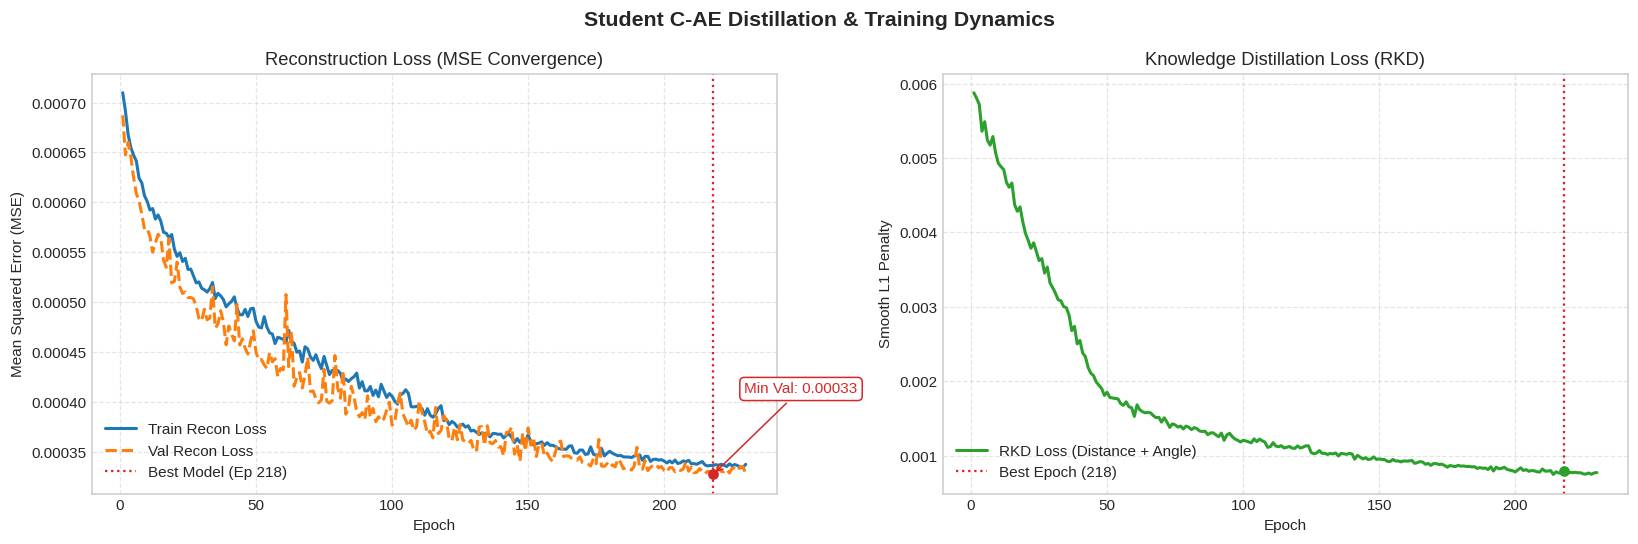

In [15]:
# @title 7. visualize charts during training

df = pd.DataFrame(history)
df["epoch"] = df.get("epoch", np.arange(len(df))) + 1

best_idx = df["val_recon_loss"].idxmin()
best_epoch = df.loc[best_idx, "epoch"]
best_val_loss = df.loc[best_idx, "val_recon_loss"]

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), dpi=110)

# Reconstruction loss
ax1.plot(df["epoch"], df["recon_loss"], label="Train Recon Loss", color="#1f77b4", lw=2)
ax1.plot(df["epoch"], df["val_recon_loss"], label="Val Recon Loss", color="#ff7f0e", ls="--", lw=2)
ax1.axvline(best_epoch, color="#d62728", ls=":", label=f"Best Model (Ep {best_epoch})")
ax1.scatter(best_epoch, best_val_loss, color="#d62728", zorder=5)
ax1.annotate(
    f"Min Val: {best_val_loss:.5f}",
    xy=(best_epoch, best_val_loss),
    xytext=(best_epoch + len(df) * 0.05, best_val_loss * 1.25),
    arrowprops={"arrowstyle": "->", "color": "#d62728"},
    color="#d62728",
    bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": "#d62728"},
)
ax1.set(
    title="Reconstruction Loss (MSE Convergence)",
    xlabel="Epoch",
    ylabel="Mean Squared Error (MSE)",
)

# RKD loss
rkd_at_best = df.loc[best_idx, "rkd_loss"]
ax2.plot(df["epoch"], df["rkd_loss"], label="RKD Loss (Distance + Angle)", color="#2ca02c", lw=2)
ax2.axvline(best_epoch, color="#d62728", ls=":", label=f"Best Epoch ({best_epoch})")
ax2.scatter(best_epoch, rkd_at_best, color="#2ca02c", zorder=5)
ax2.set(
    title="Knowledge Distillation Loss (RKD)",
    xlabel="Epoch",
    ylabel="Smooth L1 Penalty",
)

for ax in (ax1, ax2):
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Student C-AE Distillation & Training Dynamics", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

       MODEL EVALUATION SUMMARY
 • Eval set size : 2102
 • ROC-AUC Score : 1.0000
 • Threshold (ENV_FLOOR): 0.000589
 • Threshold (ENV_TABLE): 0.000591
 • Accuracy      : 99.71%
 • Precision     : 99.49%
 • Recall        : 100.00%
 • F1-Score      : 0.9974


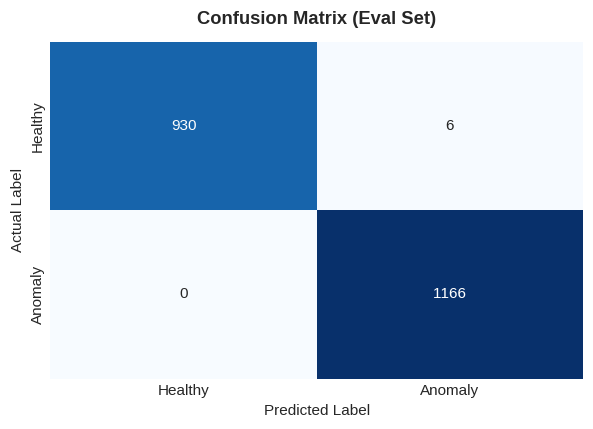

In [18]:
# @title 6. Thresholds setting & Evaluation:

def compute_errors_from_arrays(X_arr, C_arr):
    X_root = np.sqrt(np.clip(X_arr, 0, None)).reshape(-1, NUM_CHANNELS, NUM_BINS)
    X_norm = X_root / (np.linalg.norm(X_root, axis=2, keepdims=True) + EPS)

    x = torch.tensor(X_norm, dtype=torch.float32).to(device)
    c = torch.tensor(C_arr, dtype=torch.float32).to(device)

    student_model.eval()
    with torch.no_grad():
        rec, _ = student_model(x, c)
        err = ((rec - x) ** 2).mean(dim=(1, 2)).cpu().numpy()
    return err

def compute_errors(df):
    return compute_errors_from_arrays(df[cols].to_numpy("float32"), df[cond_cols].to_numpy("float32"))

val_errors = compute_errors_from_arrays(X_val_raw, C_val)
env_cols = ["env_floor", "env_table"]
THRESHOLD_BOOST = 1.00

dynamic_thresholds = {
    e: (np.percentile(val_errors[C_val[:, i] == 1.0], 99.0) if np.any(C_val[:, i] == 1.0) else np.percentile(val_errors, 99.0)) * THRESHOLD_BOOST
    for i, e in enumerate(env_cols)
}

df_eval = pd.read_csv(TEST_PATH)
df_eval["error"] = compute_errors(df_eval)

y_true = (df_eval["fault_type"] != "normal").astype(int).values
y_pred = np.zeros(len(df_eval), dtype=int)
for e in env_cols:
    mask_env = df_eval[e] == 1.0
    y_pred[mask_env] = (df_eval.loc[mask_env, "error"] > dynamic_thresholds[e]).astype(int)

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, zero_division=0)
rec = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_true, df_eval["error"].to_numpy())
cm = confusion_matrix(y_true, y_pred)

print("=" * 45)
print("       MODEL EVALUATION SUMMARY")
print("=" * 45)
print(f" • Eval set size : {len(y_true)}")
print(f" • ROC-AUC Score : {roc_auc:.4f}")
for env_name, th_val in dynamic_thresholds.items():
    print(f" • Threshold ({env_name.upper()}): {th_val:.6f}")
print(f" • Accuracy      : {acc * 100:.2f}%")
print(f" • Precision     : {prec * 100:.2f}%")
print(f" • Recall        : {rec * 100:.2f}%")
print(f" • F1-Score      : {f1:.4f}")
print("=" * 45)

plt.figure(figsize=(5.5, 4), dpi=110)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["Healthy", "Anomaly"], yticklabels=["Healthy", "Anomaly"],
)
plt.title("Confusion Matrix (Eval Set)", fontweight="bold", pad=12)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

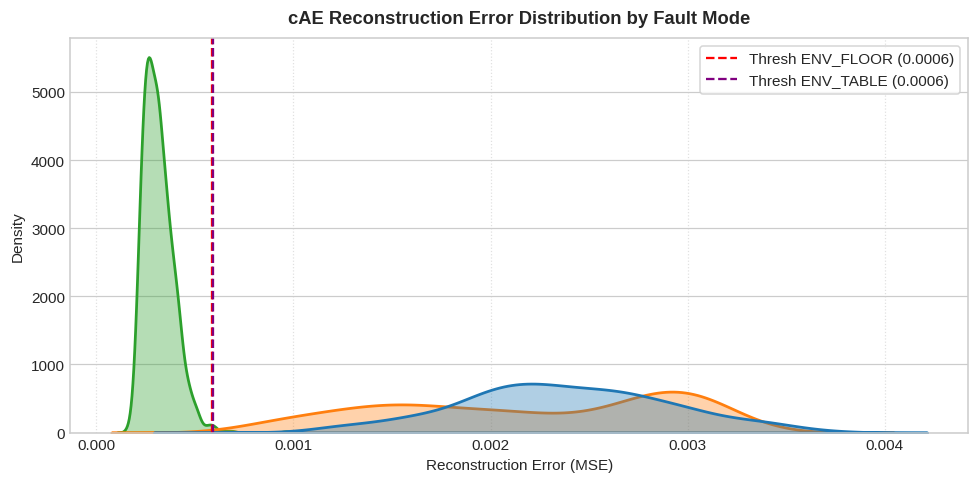

In [19]:
# @title 7. Density plot for reconstruction errors by fault mode
labels = (
    df_eval["fault_type"]
    .astype(str)
    .str.lower()
    .replace({"0": "healthy", "0.0": "healthy", "normal": "healthy", "1": "imbalanced"})
)
labels = labels.where(labels.isin(["healthy", "imbalanced", "obstruction"]), "imbalanced")

palette = {"healthy": "#2ca02c", "imbalanced": "#ff7f0e", "obstruction": "#1f77b4"}

plt.figure(figsize=(9, 4.5), dpi=110)
sns.kdeplot(
    data=df_eval,
    x="error",
    hue=labels,
    common_norm=False,
    fill=True,
    alpha=0.35,
    linewidth=1.8,
    palette={k: v for k, v in palette.items() if k in labels.unique()},
)

colors = ["red", "purple"]
for i, (env, th) in enumerate(dynamic_thresholds.items()):
    plt.axvline(th, color=colors[i % len(colors)], ls="--", lw=1.5, label=f"Thresh {env.upper()} ({th:.4f})")

plt.legend(loc="upper right", frameon=True)
plt.title("cAE Reconstruction Error Distribution by Fault Mode", fontweight="bold", pad=10)
plt.xlabel("Reconstruction Error (MSE)")
plt.ylabel("Density")
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

In [20]:
# @title 8. magnitude-based pruning

# Load best checkpoint to guarantee clean state across runs
student_model.load_state_dict(
    torch.load("best_student_esp32_model.pth", map_location=device, weights_only=True)
)

TARGET_CONVS = [
    student_model.enc[0],  # enc_conv1
    student_model.enc[3],  # enc_conv2
    student_model.enc[7],  # enc_conv3
]

PRUNE_ROUNDS = 5
PRUNE_RATIO = 0.06
FINE_TUNE_EPOCHS = 8
BASE_LR = 1e-4

optimizer_prune = torch.optim.Adam(student_model.parameters(), lr=BASE_LR)

print(f"Starting magnitude-based pruning ({PRUNE_ROUNDS} rounds x {FINE_TUNE_EPOCHS} epochs)\n" + "=" * 55)

for rnd in range(1, PRUNE_ROUNDS + 1):
    for conv in TARGET_CONVS:
        prune.l1_unstructured(conv, name="weight", amount=PRUNE_RATIO)

    student_model.train()
    for ep in range(1, FINE_TUNE_EPOCHS + 1):
        for x, c in train_loader:
            x, c = x.to(device), c.to(device)

            with torch.no_grad():
                _, t_lat = teacher_model(x, c)

            optimizer_prune.zero_grad()
            s_rec, s_lat = student_model(x, c)

            loss = (
                criterion_mse(s_rec, x)
                + criterion_rkd_dist(s_lat, t_lat)
                + 2.0 * criterion_rkd_angle(s_lat, t_lat)
            )
            loss.backward()
            optimizer_prune.step()

    student_model.eval()
    with torch.no_grad():
        val_mse = sum(
            criterion_mse(student_model(vx.to(device), vc.to(device))[0], vx.to(device)).item()
            for vx, vc in val_loader
        ) / len(val_loader)

    total_zeros = sum((conv.weight == 0).sum().item() for conv in TARGET_CONVS)
    total_weights = sum(conv.weight.numel() for conv in TARGET_CONVS)
    current_sparsity = (total_zeros / total_weights) * 100

    print(f"Round {rnd}/{PRUNE_ROUNDS} | Sparsity: {current_sparsity:.1f}% | Val MSE: {val_mse:.6f}")

for conv in TARGET_CONVS:
    prune.remove(conv, "weight")

torch.save(student_model.state_dict(), "pruned_student_esp32_model.pth")
print("Pruning successfully!")

Starting magnitude-based pruning (5 rounds x 8 epochs)
Round 1/5 | Sparsity: 6.0% | Val MSE: 0.000325
Round 2/5 | Sparsity: 11.6% | Val MSE: 0.000327
Round 3/5 | Sparsity: 16.9% | Val MSE: 0.000327
Round 4/5 | Sparsity: 21.9% | Val MSE: 0.000324
Round 5/5 | Sparsity: 26.6% | Val MSE: 0.000327
Pruning successfully!


       CONFUSION MATRIX (PRUNED STUDENT C-AE) SUMMARY
 • Accuracy : 99.90%
 • Precision: 0.9983
 • Recall   : 1.0000
 • F1-Score : 0.9991
 • ROC-AUC  : 1.0000


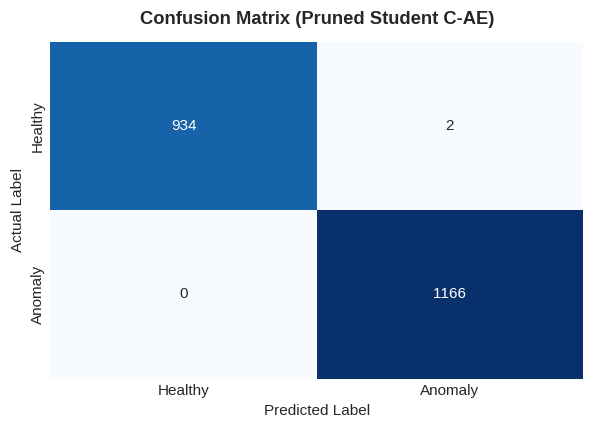

In [21]:
# Reusable evaluation utility (can also be invoked for Cell 20 / INT8 evaluation)
def evaluate_reconstruction_model(
    model,
    data_df: pd.DataFrame,
    thresholds: dict,
    error_col: str = "pruned_error",
    title: str = "Confusion Matrix",
):
    # Compute reconstruction errors via shared preprocessing pipeline
    data_df[error_col] = compute_errors(data_df)

    y_true = (data_df["fault_type"] != "normal").astype(int).values
    y_pred = np.zeros(len(data_df), dtype=int)

    for env_name in thresholds.keys():
        mask_env = data_df[env_name] == 1.0
        y_pred[mask_env] = (data_df.loc[mask_env, error_col] > thresholds[env_name]).astype(int)

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, data_df[error_col].to_numpy())
    cm = confusion_matrix(y_true, y_pred)

    print("=" * 45)
    print(f"       {title.upper()} SUMMARY")
    print("=" * 45)
    print(f" • Accuracy : {acc * 100:.2f}%")
    print(f" • Precision: {prec:.4f}")
    print(f" • Recall   : {rec:.4f}")
    print(f" • F1-Score : {f1:.4f}")
    print(f" • ROC-AUC  : {roc_auc:.4f}")
    print("=" * 45)

    plt.figure(figsize=(5.5, 4), dpi=110)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Healthy", "Anomaly"],
        yticklabels=["Healthy", "Anomaly"],
    )
    plt.title(title, fontweight="bold", pad=12)
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

    return y_pred, cm


# Cell 14: Evaluate pruned PyTorch student model
student_model.load_state_dict(
    torch.load("pruned_student_esp32_model.pth", map_location=device, weights_only=True)
)
student_model.eval()

df_eval = pd.read_csv(TEST_PATH)
y_pred_pruned, cm_pruned = evaluate_reconstruction_model(
    model=student_model,
    data_df=df_eval,
    thresholds=dynamic_thresholds,
    error_col="pruned_error",
    title="Confusion Matrix (Pruned Student C-AE)",
)

In [22]:
# @title 10. Convert model to Keras

# Load pruned model's weights
pt_model = Student1DCNN(
    in_channels=3, 
    num_bins=128, 
    latent_dim=16, 
    cond_dim=2, 
    bottleneck_channels=8
)
pt_model.load_state_dict(
    torch.load("pruned_student_esp32_model.pth", map_location="cpu", weights_only=True)
)
pt_model.eval()

# Static Inputs (batch_size=1, height=1, width=128, channels=3)
inp_x = tf.keras.Input(batch_shape=(1, 1, 128, 3), name="input_x")
inp_c = tf.keras.Input(batch_shape=(1, 2), name="input_c")

# 2D Encoder (Replaces 1D layers to eliminate EXPAND_DIMS)
enc_c1 = tf.keras.layers.Conv2D(16, (1, 5), padding="same", name="enc_c1")
enc_bn1 = tf.keras.layers.BatchNormalization(epsilon=1e-5, momentum=0.1, name="enc_bn1")
enc_c2 = tf.keras.layers.Conv2D(32, (1, 3), padding="same", name="enc_c2")
enc_bn2 = tf.keras.layers.BatchNormalization(epsilon=1e-5, momentum=0.1, name="enc_bn2")
enc_c3 = tf.keras.layers.Conv2D(32, (1, 3), padding="same", name="enc_c3")
enc_c4 = tf.keras.layers.Conv2D(8, (1, 1), name="enc_c4")

x = tf.keras.layers.ReLU()(enc_bn1(enc_c1(inp_x)))
x = tf.keras.layers.MaxPool2D((1, 2), strides=(1, 2))(tf.keras.layers.ReLU()(enc_bn2(enc_c2(x))))
x = tf.keras.layers.MaxPool2D((1, 2), strides=(1, 2))(tf.keras.layers.ReLU()(enc_c3(x)))
x = tf.keras.layers.ReLU()(enc_c4(x))  # Shape: (1, 1, 32, 8)

# latent bottleneck
feat = tf.keras.layers.Reshape((256,))(x)
fc_lat = tf.keras.layers.Dense(16, name="fc_lat")
latent = fc_lat(tf.keras.layers.Concatenate()([feat, inp_c]))

fc_dec = tf.keras.layers.Dense(256, name="fc_dec")
d_dense = fc_dec(tf.keras.layers.Concatenate()([latent, inp_c]))
d = tf.keras.layers.Reshape((1, 32, 8))(d_dense)

# decoder expansion & TFLM-Native 2x upsampling
dec_c1 = tf.keras.layers.Conv2D(32, (1, 1), name="dec_c1")
d = tf.keras.layers.ReLU()(dec_c1(d))  # Shape: (1, 1, 32, 32)

def upsample_2x_width(tensor, width, channels):
    t_expanded = tf.keras.layers.Reshape((1, width, 1, channels))(tensor)
    t_dup = tf.keras.layers.Concatenate(axis=3)([t_expanded, t_expanded])
    return tf.keras.layers.Reshape((1, 2 * width, channels))(t_dup)

d_up1 = upsample_2x_width(d, 32, 32)  # (1, 1, 64, 32)
dec_c2 = tf.keras.layers.Conv2D(32, (1, 3), padding="same", name="dec_c2")
d = tf.keras.layers.ReLU()(dec_c2(d_up1))

d_up2 = upsample_2x_width(d, 64, 32)  # (1, 1, 128, 32)
dec_c3 = tf.keras.layers.Conv2D(16, (1, 3), padding="same", name="dec_c3")
d = tf.keras.layers.ReLU()(dec_c3(d_up2))

dec_c4 = tf.keras.layers.Conv2D(3, (1, 3), padding="same", name="dec_c4")
rec = dec_c4(d)  # Shape: (1, 1, 128, 3)

keras_2d_model = tf.keras.Model(inputs=[inp_x, inp_c], outputs=[rec, latent])

# PyTorch -> Keras
c2k_2d = lambda c: [
    np.expand_dims(c.weight.detach().numpy().transpose(2, 1, 0), axis=0),
    c.bias.detach().numpy(),
]
bn2k = lambda b: [
    b.weight.detach().numpy(),
    b.bias.detach().numpy(),
    b.running_mean.detach().numpy(),
    b.running_var.detach().numpy(),
]

enc_c1.set_weights(c2k_2d(pt_model.enc[0]))
enc_bn1.set_weights(bn2k(pt_model.enc[1]))
enc_c2.set_weights(c2k_2d(pt_model.enc[3]))
enc_bn2.set_weights(bn2k(pt_model.enc[4]))
enc_c3.set_weights(c2k_2d(pt_model.enc[7]))
enc_c4.set_weights(c2k_2d(pt_model.enc[10]))

# Align channel-first flatten to channel-last flatten for Dense layers
w_l = pt_model.fc_latent.weight.detach().numpy()
w_feat = w_l[:, :256].reshape(16, 8, 32).transpose(0, 2, 1).reshape(16, 256)
fc_lat.set_weights([
    np.hstack([w_feat, w_l[:, 256:]]).T,
    pt_model.fc_latent.bias.detach().numpy(),
])

w_d = pt_model.fc_dec.weight.detach().numpy().reshape(8, 32, 18).transpose(1, 0, 2).reshape(256, 18).T
b_d = pt_model.fc_dec.bias.detach().numpy().reshape(8, 32).T.reshape(256)
fc_dec.set_weights([w_d, b_d])

dec_c1.set_weights(c2k_2d(pt_model.dec_expand[0]))
dec_c2.set_weights(c2k_2d(pt_model.dec[1]))
dec_c3.set_weights(c2k_2d(pt_model.dec[4]))
dec_c4.set_weights(c2k_2d(pt_model.dec[6]))

# numerical checking
np.random.seed(42)
test_x = np.random.randn(1, 3, 128).astype(np.float32)
test_c = np.random.randn(1, 2).astype(np.float32)

with torch.no_grad():
    pt_r, pt_l = pt_model(torch.from_numpy(test_x), torch.from_numpy(test_c))

# Keras input shape: (1, 1, 128, 3)
keras_in_x = np.expand_dims(test_x.transpose(0, 2, 1), axis=1)
tf_r, tf_l = keras_2d_model([keras_in_x, test_c])

diff_rec = np.max(np.abs(np.expand_dims(pt_r.numpy().transpose(0, 2, 1), axis=1) - tf_r.numpy()))
diff_lat = np.max(np.abs(pt_l.numpy() - tf_l.numpy()))

assert diff_rec < 1e-4, f"Parity check failed for reconstruction: {diff_rec:.2e}"
assert diff_lat < 1e-4, f"Parity check failed for latent: {diff_lat:.2e}"
print(f"✓ 2D Parity test passed! Max diff: rec={diff_rec:.2e}, lat={diff_lat:.2e}")

I0000 00:00:1792473197.466311      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13562 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792473197.469004      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


✓ 2D Parity test passed! Max diff: rec=1.52e-06, lat=1.19e-07


In [23]:
# (1, 1, 128, 3)
def representative_data_gen():
    num_samples = min(200, len(X_train))
    for i in range(num_samples):
        sample_x = np.expand_dims(X_train[i : i + 1].transpose(0, 2, 1), axis=1).astype(np.float32)
        sample_c = C_train[i : i + 1].astype(np.float32)
        yield {
            "input_x": sample_x,
            "input_c": sample_c
        }

# TFLite int8 converter
converter = tf.lite.TFLiteConverter.from_keras_model(keras_2d_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data_gen
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_quant_model = converter.convert()

tflite_filename = "student_esp32_int8.tflite"
with open(tflite_filename, "wb") as f:
    f.write(tflite_quant_model)

file_size_kb = len(tflite_quant_model) / 1024
print(f"✓ Model successfully quantized: {tflite_filename} ({file_size_kb:.2f} KB)")

INFO:tensorflow:Assets written to: /tmp/tmp7wdqej_r/assets


INFO:tensorflow:Assets written to: /tmp/tmp7wdqej_r/assets


Saved artifact at '/tmp/tmp7wdqej_r'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(1, 1, 128, 3), dtype=tf.float32, name='input_x'), TensorSpec(shape=(1, 2), dtype=tf.float32, name='input_c')]
Output Type:
  List[TensorSpec(shape=(1, 1, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(1, 16), dtype=tf.float32, name=None)]
Captures:
  137275040355280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137275040356624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137275040354704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137275040356240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137275040355664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137275040353936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137275040353360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137275040353168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137275040355088: TensorSpec(sha

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


✓ Model successfully quantized: student_esp32_int8.tflite (39.38 KB)


W0000 00:00:1792473205.616130      58 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792473205.616153      58 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792473205.634633      58 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


In [24]:
# @title 11. Verification for ops (since I got so many bugs)
def verify_tflm_compliance(model_bytes):
    interpreter = tf.lite.Interpreter(model_content=model_bytes)
    interpreter.allocate_tensors()

    allowed_ops = {
        "CONV_2D",
        "MAX_POOL_2D",
        "FULLY_CONNECTED",
        "RESHAPE",
        "CONCATENATION",
        "QUANTIZE",
        "DELEGATE"  # Internal runtime CPU delegate wrapper
    }

    # Ban ops that cause bugs
    forbidden_ops = {"EXPAND_DIMS", "TILE", "SHAPE", "PACK", "STRIDED_SLICE"}

    ops_details = interpreter._get_ops_details()
    present_ops = set(op["op_name"] for op in ops_details)

    print(f"Operators detected in model: {sorted(list(present_ops))}")

    # check for forbidden dynamic ops
    detected_forbidden = present_ops.intersection(forbidden_ops)
    assert not detected_forbidden, (
        f"DEPLOYMENT ABORTED: Found unsupported ops: {detected_forbidden}. "
        "Dynamic shape operations detected."
    )

    # check that all detected ops are within the allowlist
    unsupported = present_ops.difference(allowed_ops)
    assert not unsupported, (
        f"DEPLOYMENT ABORTED: Operators {unsupported} are not in the ESP32 allowlist."
    )

    # I/O verification
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    inp_x_meta = next((inp for inp in input_details if "input_x" in inp["name"]), None)
    inp_c_meta = next((inp for inp in input_details if "input_c" in inp["name"]), None)

    assert inp_x_meta is not None, "Error: 'input_x' tensor not found in model inputs"
    assert inp_c_meta is not None, "Error: 'input_c' tensor not found in model inputs"

    assert inp_x_meta["shape"].tolist() == [1, 1, 128, 3], (
        f"input_x shape mismatch: expected [1, 1, 128, 3], got {inp_x_meta['shape'].tolist()}"
    )
    assert inp_c_meta["shape"].tolist() == [1, 2], (
        f"input_c shape mismatch: expected [1, 2], got {inp_c_meta['shape'].tolist()}"
    )

    assert inp_x_meta["dtype"] == np.int8, "input_x must be quantized as int8"
    assert inp_c_meta["dtype"] == np.int8, "input_c must be quantized as int8"
    assert output_details[0]["dtype"] == np.int8, "Output tensor must be int8"

    print("All passed")

verify_tflm_compliance(tflite_quant_model)

Operators detected in model: ['CONCATENATION', 'CONV_2D', 'DELEGATE', 'FULLY_CONNECTED', 'MAX_POOL_2D', 'QUANTIZE', 'RESHAPE']
All passed


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [25]:
# @title 12. Export headers

tflite_filename = "student_esp32_int8.tflite"
header_filename = "model_data.h"

with open(tflite_filename, "rb") as f:
    tflite_bytes = f.read()

model_len = len(tflite_bytes)

with open(header_filename, "w") as f:
    f.write("#ifndef MODEL_DATA_H_\n")
    f.write("#define MODEL_DATA_H_\n\n")
    f.write("#include <stdint.h>\n\n")
    f.write(f"const unsigned int g_model_len = {model_len};\n")
    # alignas(16) is compulsory for mapping directly from Flash
    f.write("alignas(16) const unsigned char g_model[] = {\n")

    # Ghi định dạng 12 byte hệ hex trên mỗi dòng
    for i in range(0, model_len, 12):
        chunk = tflite_bytes[i : i + 12]
        hex_str = ", ".join(f"0x{b:02x}" for b in chunk)
        f.write(f"    {hex_str},\n")

    f.write("};\n\n")
    f.write("#endif // MODEL_DATA_H_\n")

header_size_kb = os.path.getsize(header_filename) / 1024
print(f"{header_filename} ({header_size_kb:.2f} KB, model's size: {model_len} bytes)")

model_data.h (249.60 KB, model's size: 40328 bytes)


In [28]:
# @title 12.1. To download all models into one zip file

working_dir = "/kaggle/working"
zip_filename = "esp32_project_artifacts.zip"
zip_filepath = os.path.join(working_dir, zip_filename)

target_files = [
    "student_esp32_int8.tflite",
    "model_data.h",
    "pruned_student_esp32_model.pth",
    "best_student_esp32_model.pth",
]

if os.path.exists(zip_filepath):
    os.remove(zip_filepath)

packaged_count = 0
with zipfile.ZipFile(zip_filepath, "w", zipfile.ZIP_DEFLATED) as zipf:
    for fname in target_files:
        fpath = os.path.join(working_dir, fname)
        if os.path.exists(fpath):
            file_size_kb = os.path.getsize(fpath) / 1024
            zipf.write(fpath, arcname=fname)
            packaged_count += 1
            print(f"Added: {fname:<30} ({file_size_kb:.2f} KB)")
        else:
            print(f"Not found {fname}")

if packaged_count > 0:
    total_zip_kb = os.path.getsize(zip_filepath) / 1024
    print(f"Successfully: {zip_filename} ({total_zip_kb:.2f} KB)")
    display(FileLink(zip_filename))
else:
    print("\nCannot find any files")

Added: student_esp32_int8.tflite      (39.38 KB)
Added: model_data.h                   (249.60 KB)
Added: pruned_student_esp32_model.pth (86.99 KB)
Added: best_student_esp32_model.pth   (86.92 KB)
Successfully: esp32_project_artifacts.zip (212.68 KB)


/kaggle/working/esp32_project_artifacts.zip

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Recalibrated INT8 Thresholds:
 • ENV_FLOOR: 0.000984
 • ENV_TABLE: 0.000942
       CONFUSION MATRIX (INT8 QUANTIZED STUDENT C-AE) SUMMARY
 • Accuracy : 98.81%
 • Precision: 1.0000
 • Recall   : 0.9786
 • F1-Score : 0.9892
 • ROC-AUC  : 1.0000


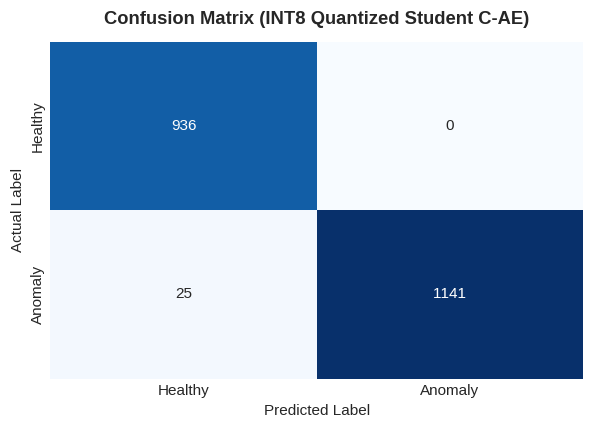

In [32]:
# @title 13. INT8 TFLite Model Evaluation & Confusion Matrix

# Resolve TFLite model from in-memory buffer or disk artifact
interpreter_args = {}
if "tflite_model" in globals() and isinstance(tflite_model, (bytes, bytearray)):
    interpreter_args["model_content"] = tflite_model
else:
    model_path = "/kaggle/working/student_esp32_int8.tflite"
    if not model_path:
        raise FileNotFoundError(
            "Could not locate TFLite model in memory ('tflite_model') or on disk."
        )
    interpreter_args["model_path"] = model_path

interpreter = tf.lite.Interpreter(**interpreter_args)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

inp_x_meta = next(
    inp for inp in input_details if "input_x" in inp["name"] or np.prod(inp["shape"]) == 384
)
inp_c_meta = next(
    inp for inp in input_details if "input_c" in inp["name"] or np.prod(inp["shape"]) == 2
)
out_rec_meta = next(out for out in output_details if np.prod(out["shape"]) == 384)

idx_x, scale_x, zp_x = inp_x_meta["index"], inp_x_meta["quantization"][0], inp_x_meta["quantization"][1]
idx_c, scale_c, zp_c = inp_c_meta["index"], inp_c_meta["quantization"][0], inp_c_meta["quantization"][1]
idx_rec, scale_rec, zp_rec = (
    out_rec_meta["index"],
    out_rec_meta["quantization"][0],
    out_rec_meta["quantization"][1],
)


def compute_tflite_errors(X_input: np.ndarray, C_input: np.ndarray) -> np.ndarray:
    if X_input.ndim == 2:
        X_root = np.sqrt(np.clip(X_input, 0, None)).reshape(-1, 3, 128)
        X_norm = (X_root / (np.linalg.norm(X_root, axis=2, keepdims=True) + 1e-8)).astype(np.float32)
    else:
        X_norm = X_input.astype(np.float32)

    X_cl = np.expand_dims(X_norm.transpose(0, 2, 1), axis=1)
    C_arr = C_input.astype(np.float32)

    num_samples = len(X_cl)
    errors = np.empty(num_samples, dtype=np.float32)

    for i in range(num_samples):
        q_x = np.clip(np.round(X_cl[i : i + 1] / scale_x) + zp_x, -128, 127).astype(np.int8)
        q_c = np.clip(np.round(C_arr[i : i + 1] / scale_c) + zp_c, -128, 127).astype(np.int8)

        interpreter.set_tensor(idx_x, q_x)
        interpreter.set_tensor(idx_c, q_c)
        interpreter.invoke()

        q_rec = interpreter.get_tensor(idx_rec)

        deq_x = (q_x.astype(np.float32) - zp_x) * scale_x
        deq_rec = (q_rec.astype(np.float32) - zp_rec) * scale_rec
        errors[i] = np.mean((deq_x - deq_rec) ** 2)

    return errors


# Compute dynamic thresholds on validation set (99th percentile)
val_errors_int8 = compute_tflite_errors(X_val_raw, C_val)
dynamic_thresholds_int8 = {
    env: float(np.percentile(val_errors_int8[C_val[:, i] == 1.0], 99.0))
    for i, env in enumerate(cond_cols)
}

print("Recalibrated INT8 Thresholds:")
for env, th in dynamic_thresholds_int8.items():
    print(f" • {env.upper()}: {th:.6f}")

# Evaluate on test set
df_test = pd.read_csv(TEST_PATH)
df_test["int8_error"] = compute_tflite_errors(
    df_test[cols].to_numpy(np.float32), df_test[cond_cols].to_numpy(np.float32)
)

y_pred_int8, cm_int8 = evaluate_reconstruction_model(
    model=None,
    data_df=df_test,
    thresholds=dynamic_thresholds_int8,
    error_col="int8_error",
    title="Confusion Matrix (INT8 Quantized Student C-AE)",
)